<table style="width: 100%; margin-left: auto; margin-right: auto; background-color: white;">
<tbody>
<tr>

<td style="text-align: center; width: 12%;"><img src=img/brasil-brasao.png alt="" /></td>

<td style="width: 68%;">
<h2 style="text-align: center; margin-top: 1%;">Rep&uacute;blica Federativa do Brasil</h2>
<h2 style="text-align: center; margin-top: 1%;">Minist&eacute;rio da Educa&ccedil;&atilde;o</h2>
<h2 style="text-align: center; margin-top: 1%;">Universidade Federal do Amazonas</h2>
<h2 style="text-align: center; margin-top: 1%;">Instituto de Computa&ccedil;&atilde;o</h2>
</td>

<td style="width: 12%;"><img src="img/UFAM-logo.png" alt="" /></td>

</tr>
</tbody>
</table>

---

# Ciência de Dados
## Trabalho Prático I: Exploração de Dados

_Professor Dr. Marco Cristo_

**Alunos:**  `Sarah Lima, Nome Sobrenome e Nome Sobrenome` <br>
**E-mail:** `sarah.lima@icomp.ufam.edu.br, nome.sobrenome@icomp.ufam.edu.br e nome.sobrenome@icomp.ufam.edu.br`

#### Preliminares

In [13]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import sklearn
import sys
import os 

In [14]:
print("Python", sys.version)
print("--------")
print("Pandas:", pd.__version__)
print("Numpy:", np.__version__)
print("SKLearn:", sklearn.__version__)

Python 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
--------
Pandas: 2.3.3
Numpy: 2.3.2
SKLearn: 1.7.2


In [15]:
DATA_PQT = 'data/enem2019.parquet' 
MUNICIPIO_PROVA = 'São José dos Campos' # Use o município que foi especificado para sua equipe. 

In [16]:
# Caminho do arquivo
df_enem = pd.read_parquet(DATA_PQT)
df_enem.shape

(599982, 56)

----
#### Qualidade de dados

<div class="alert alert-info">
    <b>1</b> - Quais colunas possuem campos nulos em <code>df_enem</code>?<br><i>Dica</i>: Há muitas formas de fazer isso em Pandas, como por exemplo através da utilização do método `isnull()`.
</div>

In [17]:
#Exibe as colunas que possuem campos nulos
display(df_enem.columns[df_enem.isnull().any()].tolist())

['NO_MUNICIPIO_NASCIMENTO',
 'SG_UF_NASCIMENTO',
 'TP_ENSINO',
 'CO_PROVA_CN',
 'CO_PROVA_CH',
 'CO_PROVA_LC',
 'CO_PROVA_MT',
 'NU_NOTA_CN',
 'NU_NOTA_CH',
 'NU_NOTA_LC',
 'NU_NOTA_MT',
 'TP_STATUS_REDACAO',
 'NU_NOTA_REDACAO']

In [18]:
df_enem

,NO_MUNICIPIO_RESIDENCIA,SG_UF_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_NACIONALIDADE,NO_MUNICIPIO_NASCIMENTO,SG_UF_NASCIMENTO,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,...,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025
0,Votorantim,SP,20,M,1,1,Sorocaba,SP,1,3,...,A,A,A,A,A,A,B,A,A,A
1,Sorocaba,SP,17,F,1,1,Sorocaba,SP,2,0,...,B,B,A,B,A,A,D,A,B,B
2,Sorocaba,SP,23,M,2,1,Mandaguari,PR,1,2,...,A,A,B,B,A,B,C,B,B,B
3,Sorocaba,SP,17,M,1,1,Sorocaba,SP,2,0,...,B,A,A,B,A,A,B,A,B,B
4,Sorocaba,SP,17,M,1,1,Sorocaba,SP,2,0,...,B,B,A,C,B,B,E,B,E,B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599977,Manaus,AM,36,F,0,1,Manaus,AM,1,13,...,A,A,A,A,A,A,B,A,A,B
599978,Manaus,AM,31,F,1,1,Alenquer,PA,1,12,...,A,A,A,B,A,A,D,A,A,A
599979,Manaus,AM,16,M,1,1,Manaus,AM,3,0,...,A,A,A,B,B,A,B,A,A,B
599980,Manaus,AM,39,M,2,1,Belém,PA,1,13,...,A,A,A,C,A,B,C,B,B,B


<div class="alert alert-info">
<b>2</b> - Remova todas as instâncias que não possuem valores para as colunas <code>NO_MUNICIPIO_NASCIMENTO</code> ou <code>SG_UF_NASCIMENTO</code> Para as colunas <code>CO_PROVA_CN</code>, <code>CO_PROVA_CH</code>, <code>CO_PROVA_LC</code>, <code>CO_PROVA_MT</code> e <code>TP_STATUS_REDACAO</code>, remova apenas as instâncias onde todos esses valores encontram-se ausentes.<br><i>Dica</i>: Os argumentos `subset` e `how`, do método `dropna()` do Pandas podem lhe ajudar.
</div>

In [19]:
df_enem = df_enem.dropna(subset=['NO_MUNICIPIO_NASCIMENTO', 'SG_UF_NASCIMENTO'], how='any')
df_enem = df_enem.dropna(subset=['CO_PROVA_CN','CO_PROVA_CH','CO_PROVA_LC','CO_PROVA_MT','TP_STATUS_REDACAO'], how='all')
df_enem

,NO_MUNICIPIO_RESIDENCIA,SG_UF_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_NACIONALIDADE,NO_MUNICIPIO_NASCIMENTO,SG_UF_NASCIMENTO,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,...,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025
0,Votorantim,SP,20,M,1,1,Sorocaba,SP,1,3,...,A,A,A,A,A,A,B,A,A,A
1,Sorocaba,SP,17,F,1,1,Sorocaba,SP,2,0,...,B,B,A,B,A,A,D,A,B,B
3,Sorocaba,SP,17,M,1,1,Sorocaba,SP,2,0,...,B,A,A,B,A,A,B,A,B,B
4,Sorocaba,SP,17,M,1,1,Sorocaba,SP,2,0,...,B,B,A,C,B,B,E,B,E,B
7,Sorocaba,SP,18,F,1,1,Sorocaba,SP,2,0,...,B,A,A,B,B,A,D,A,B,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599976,Manaus,AM,25,M,2,1,Oriximiná,PA,1,5,...,A,A,A,B,B,A,C,A,A,B
599977,Manaus,AM,36,F,0,1,Manaus,AM,1,13,...,A,A,A,A,A,A,B,A,A,B
599978,Manaus,AM,31,F,1,1,Alenquer,PA,1,12,...,A,A,A,B,A,A,D,A,A,A
599980,Manaus,AM,39,M,2,1,Belém,PA,1,13,...,A,A,A,C,A,B,C,B,B,B


<div class="alert alert-info">
    <b>3</b> - Substitua dados faltantes por valores razoáveis. Valores ausentes nas colunas <code>TP_ENSINO</code> e <code>TP_STATUS_REDACAO</code> podem ser substituídos por 0 (0 = Não informado). No caso das notas, se elas forem NaN, podemos substituí-las por 0 (estamos penalizando quem faltou uma prova, mas fez as demais, em parte porque há poucos casos assim nesta base). Já os códigos do tipo de prova (<code>CO_PROVA_**</code>), quando ausentes, podem ser substuídos para 500 (_500 = Faltou à prova_). Após isso, imprima o vetor resultante para confirmar se não há mais valores NaNs. 
</div>

In [20]:
# Tratando dados faltantes
df_enem['TP_ENSINO'] = df_enem['TP_ENSINO'].fillna(value = 0)
df_enem['TP_STATUS_REDACAO'] = df_enem['TP_STATUS_REDACAO'].fillna(value=0)

# Tratando notas com campo nulo
df_enem['NU_NOTA_CN'] = df_enem['NU_NOTA_CN'].fillna(value=0)
df_enem['NU_NOTA_CH'] = df_enem['NU_NOTA_CH'].fillna(value=0)
df_enem['NU_NOTA_LC'] = df_enem['NU_NOTA_LC'].fillna(value=0)
df_enem['NU_NOTA_MT'] = df_enem['NU_NOTA_MT'].fillna(value=0)
df_enem['NU_NOTA_REDACAO'] = df_enem['NU_NOTA_REDACAO'].fillna(value=0)

# Tratando códigos do tipo de provas com campo nulo
df_enem['CO_PROVA_CN'] = df_enem['CO_PROVA_CN'].fillna(value=500)
df_enem['CO_PROVA_CH'] = df_enem['CO_PROVA_CH'].fillna(value=500)
df_enem['CO_PROVA_LC'] = df_enem['CO_PROVA_LC'].fillna(value=500)
df_enem['CO_PROVA_MT'] = df_enem['CO_PROVA_MT'].fillna(value=500)

#Exibe as colunas que possuem campos nulos
display(df_enem.columns[df_enem.isnull().any()].tolist())

[]

----
#### Análise e visualização de dados

<div class="alert alert-info">
<b>4</b> - Considerando a distribuição de notas em sua cidade de estudo, quem se saiu melhor: alunos das escolas de ensino médio públicas ou privadas? O mesmo se observa para o resto do país? Finalmente, para que provas, o desempenho das escolas públicas da sua cidade de interesse é <i>significativamente</i> pior (confiança de 95%) que a observada nas escolas do resto do país?<br><i>Dica</i>: boxplots são ótimos para comparar distribuições. Você pode verificar relevância da diferença nas notas usando um teste não paramétrico (ex: mannwhitneyu) unicaudal.
</div>

In [21]:
notas = ['NU_NOTA_CN','NU_NOTA_CH','NU_NOTA_LC','NU_NOTA_MT','NU_NOTA_REDACAO']

### Criando filtros para facilitar seleção de dados

# Selecionando somente os alunos que estudam em escolas PÚBLICAS OU PRIVADAS
alunos_publica = df_enem['TP_ESCOLA'] == 2
alunos_privada = df_enem['TP_ESCOLA'] == 3
alunos_pub_priv = alunos_publica | alunos_privada

# Selecionando somente a cidade de SJC
cidade_sjc = df_enem['NO_MUNICIPIO_NASCIMENTO'] == 'São José dos Campos'

# Selecionando o resto do país
resto_brasil = df_enem['NO_MUNICIPIO_NASCIMENTO'] != 'São José dos Campos'

### Aplicando os filtros

# Dados São José dos Campos
df_sjc = df_enem[cidade_sjc & alunos_pub_priv]

# Dados do resto do pais
df_brasil = df_enem[resto_brasil & alunos_pub_priv]

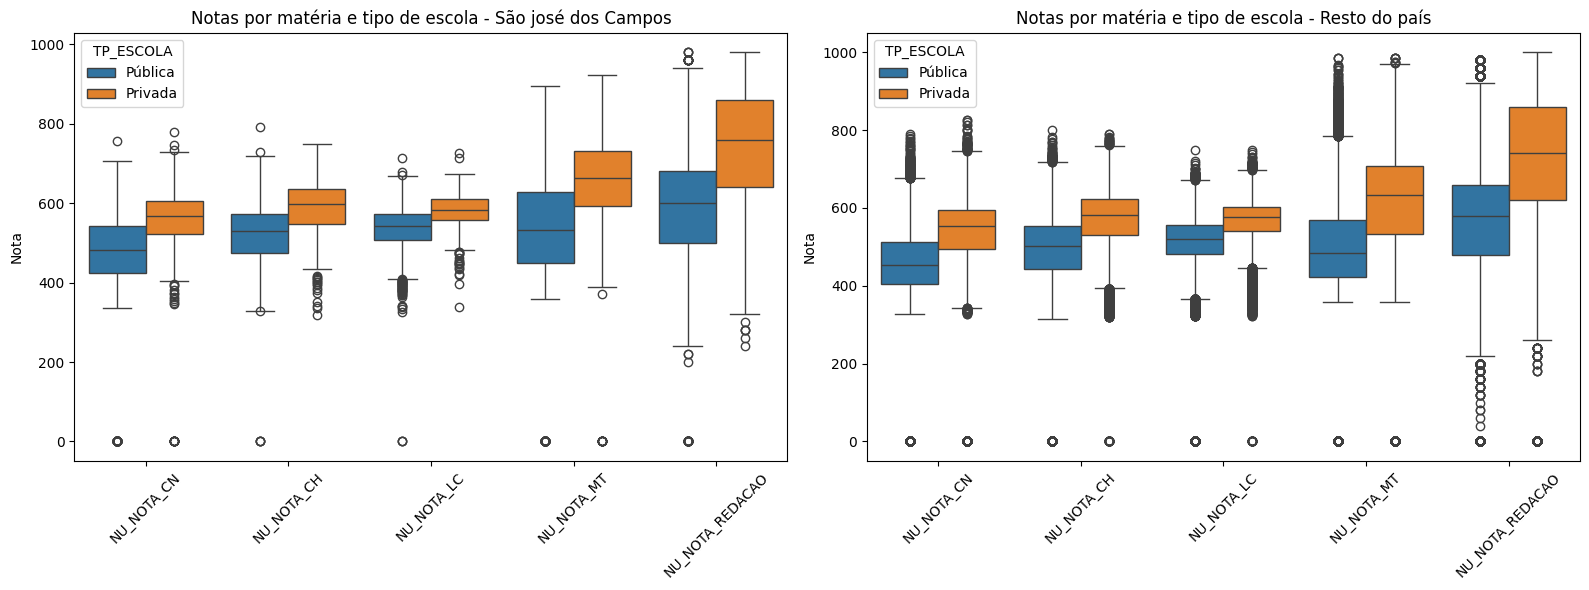

In [22]:
### Organizando os dados para melhor visualização
df_long_sjc = df_sjc.melt(
    id_vars=['TP_ESCOLA'],
    value_vars=notas,
    var_name='Matéria',
    value_name='Nota'
)

# Colocando nomes descritivos para facilitar a visualização e entedimento
df_long_sjc['TP_ESCOLA'] = df_long_sjc['TP_ESCOLA'].replace({2: 'Pública', 3: 'Privada'})

# Organizando os dados para melhor visualização
df_long_brasil = df_brasil.melt(
    id_vars=['TP_ESCOLA'],
    value_vars=notas,
    var_name='Matéria',
    value_name='Nota'
)

# Colocando nomes descritivos para facilitar a visualização e entendimento
df_long_brasil['TP_ESCOLA'] = df_long_brasil['TP_ESCOLA'].replace({2: 'Pública', 3: 'Privada'})

### Criando os gráficos
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

sns.boxplot(data=df_long_sjc, x='Matéria', y='Nota', hue='TP_ESCOLA', ax=axes[0])
axes[0].set_title('Notas por matéria e tipo de escola - São josé dos Campos')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df_long_brasil, x='Matéria', y='Nota', hue='TP_ESCOLA')
axes[1].set_title('Notas por matéria e tipo de escola - Resto do país')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [23]:
# Comparando desempenho escolas PÚBLICAS por matéria
from scipy.stats import mannwhitneyu

for materia in notas:
    # Separando as notas somente dos alunos de escola pública
    notas_sjc = df_sjc[df_sjc['TP_ESCOLA'] == 2][materia]
    notas_brasil = df_brasil[df_brasil['TP_ESCOLA'] == 2][materia]
    
    stat, p = mannwhitneyu(notas_sjc, notas_brasil, alternative='less')
    
    if p <= 0.05:
        print(f"{materia}: desempenho significativamente pior em SJC")
    else:
        print(f"{materia}: sem diferença significativa")

NU_NOTA_CN: sem diferença significativa
NU_NOTA_CH: sem diferença significativa
NU_NOTA_LC: sem diferença significativa
NU_NOTA_MT: sem diferença significativa
NU_NOTA_REDACAO: sem diferença significativa


<div class="alert alert-primary">
<b>4.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
<b>5</b> - Como se comparam os inscritos que fizeram a prova com intuito de apenas treinar seus conhecimentos com os demais? E o que se observa para o resto do país? Finalmente, para que provas de sua cidade de interesse, o desempenho dos alunos treinando é significativamente melhor (confiança de 95%) que o dos alunos fazendo a prova para valer? Novamente considere as distribuições de notas, mas desta vez use gráficos de violino e avalie diferenças de notas com o teste T de Student. 
</div> 

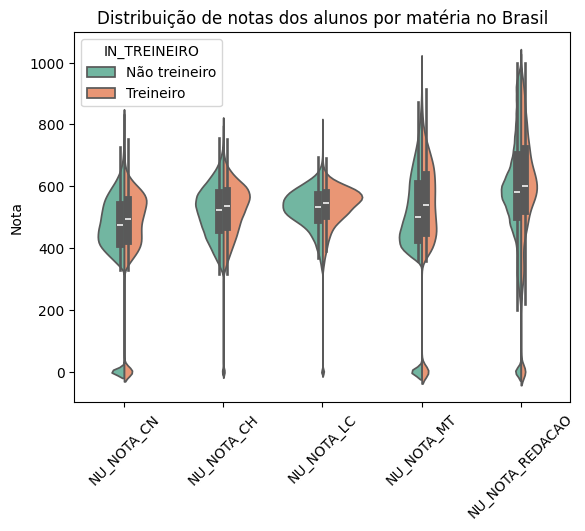

In [ ]:
# Organizando os dados para melhor visualização
df_long = df_enem.melt(
    id_vars=['IN_TREINEIRO'],
    value_vars=notas,
    var_name='Matéria',
    value_name='Nota'
)

# Colocando nomes descritivos para facilitar a visualização e entendimento
df_long['IN_TREINEIRO'] = df_long['IN_TREINEIRO'].replace({0: 'Não treineiro', 1: 'Treineiro'})

sns.violinplot(data=df_long, x='Matéria', y='Nota', hue='IN_TREINEIRO', split=True, inner='box', palette='Set2')
plt.title('Distribuição de notas dos alunos por matéria no Brasil')
plt.xlabel('')
plt.xticks(rotation=45)
plt.show()

<div class="alert alert-primary">
<b>5.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
<b>6</b> - Sobre a redação, como se comparam os desempenhos dos inscritos conforme o ano de conclusão do ensino médio em sua cidade de interesse? E no resto do país? Usando um gráfico de linhas, trace as notas médias obtidas contra o ano de conclusão.<br><i>ATENÇÃO</i>: Em `TP_ANO_CONCLUIU`, defina 2019 para todas as intâncias onde `TP_ST_CONCLUSAO` seja igual a 2 (2 = "Estou cursando e concluirei o Ensino Médio em 2019").
</div> 

<div class="alert alert-primary">
<b>6.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
    <b>7</b> - Qual a relação entre o grau de instrução dos pais (<code>Q001</code> e <code>Q002</code>) e o desempenho dos seus filhos, tanto na sua cidade de interesse quanto no resto do país? Considere a média de todas as notas do candidato como seu desempenho. 
</div> 

<div class="alert alert-primary">
<b>7.1</b> - Explique os resultados obtidos.
</div>

**Ainda considerando o desempenho calculado na questão anterior e, agora, as seguintes faixas de renda (`Q006`):**

A = Nenhuma renda.<br/>B = Até R\\$ 998,00.<br/>C = De R\\$ 998,01 até R\\$ 1.497,00.<br/>D = De R\\$ 1.497,01 até R\\$ 1.996,00.<br/>E = De R\\$ 1.996,01 até R\\$ 2.495,00.<br/>F = De R\\$ 2.495,01 até R\\$ 2.994,00.<br/>G = De R\\$ 2.994,01 até R\\$ 3.992,00.<br/>H = De R\\$ 3.992,01 até R\\$ 4.990,00.<br/>I = De R\\$ 4.990,01 até R\\$ 5.988,00.<br/>J = De R\\$ 5.988,01 até R\\$ 6.986,00.<br/>K = De R\\$ 6.986,01 até R\\$ 7.984,00.<br/>L = De R\\$ 7.984,01 até R\\$ 8.982,00.<br/>M = De R\\$ 8.982,01 até R\\$ 9.980,00.<br/>N = De R\\$ 9.980,01 até R\\$ 11.976,00.<br/>O = De R\\$ 11.976,01 até R\\$ 14.970,00.<br/>P = De R\\$ 14.970,01 até R\\$ 19.960,00.<br/>Q = Mais de R\\$ 19.960,00.<br/>

Responda:

<div class="alert alert-info">
<b>8</b> - É possível afirmar que, dos inscritos que concluem o ensino médio em 2019, os mais ricos são os que obtém o maior desempenho, tanto na sua cidade de interesse quanto no resto do país? Neste caso, além de uma inspeção visual, prove sua afirmação usando um teste de correlação de Spearman.
</div>

<div class="alert alert-primary">
<b>8.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
    <b>9</b> - Qual a nota geral média dos alunos, de acordo com o tipo de estado civil (<code>TP_ESTADO_CIVIL</code>), tanto em sua cidade de interesse quanto no resto do país?
</div>


<div class="alert alert-primary">
<b>9.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
    <b>10</b> - Qual a nota geral média dos alunos, de acordo com o tipo da lingua estrangeira escolhida (<code>TP_LINGUA</code>) tanto em sua cidade de interesse quanto no resto do país?
</div>

<div class="alert alert-primary">
<b>10.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
    <b>11</b> - Qual a nota geral média dos alunos, de acordo com ocupação dos pais/responsáveis e (<code>Q003</code> e <code>Q004</code>) tanto em sua cidade de interesse quanto no resto do país?
</div>

<div class="alert alert-primary">
<b>11.1</b> - Explique os resultados obtidos.
</div>

----
#### Transformação e Engenharia de atributos

<div class="alert alert-info">
    <b>12</b> - A partir do campo <code>NU_IDADE</code>, que armazena a idade dos inscritos, crie a coluna <code>FAIXA_ETARIA</code> com os seguintes intervalos:
    <ul>
        <li>[10..18)</li>
        <li>[18..22)</li>
        <li>[22..26)</li>
        <li>[26..33)</li>
        <li>[33..40)</li>
        <li>[40..55)</li>
        <li>[55..65)</li>
        <li>[65..70)</li>
        <li>[70..100]</li>
    </ul><i>ATENÇÃO</i>: Apague instâncias com idade inferior a 10 ou superior a 100 anos.
</div>

Considerando apenas os alunos que não faltaram a nenhuma prova (`TP_PRESENCA_**`), queremos tentar prever se um dado inscrito irá obter uma nota de redação acima ou abaixo da média, a partir das seguintes informações:

- `FAIXA_ETARIA`, `NO_MUNICIPIO_RESIDENCIA`, `TP_SEXO`, `TP_ESTADO_CIVIL`, `TP_ST_CONCLUSAO`, `TP_ANO_CONCLUIU`, `TP_ESCOLA`
- `CO_PROVA_CH`,`CO_PROVA_LC`, `NU_NOTA_CH`, `NU_NOTA_LC`, `TP_LINGUA`
- `Q001`, `Q002`, `Q003`, `Q004`, `Q005`, `Q006`, `Q021`, `Q022`, `Q024`, `Q025`
- `TARGET` 

<div class="alert alert-info">
<b>13</b> - Prepare os dados para aprendizado, convertendo strings para dados categóricos, mantendo sem mudanças os dados categóricos não numéricos e padronizando dados numéricos usando Z-score.<br><i>ATENÇÃO</i>: Você deve criar a coluna `TARGET` para ser utilizada como alvo de classificação e avaliação de atributos. Ela deve ser `1`, caso a nota da redação do aluno seja maior que a média, ou `0`, caso contrário.
</div>

<div class="alert alert-info">
<b>14</b> - Que atributos são os mais importantes considerando correlação absoluta com o alvo, ANOVA, chi quadrado, Informação Mútua e a importância das variáveis de acordo com uma floresta aleatória? Considere apenas candidatos em sua cidade de interesse.<br><i>Dica</i>: Para facilitar a visualização, coloque todas as métricas em um único dataframe. Então as normalize para que todas fiquem entre 0 e 1. Obtenha então uma média agregada das métricas normalizadas e use esta média agregada para ordenar as variáveis da mais à menos importante. 
</div>